# One-neuron dropout and the degree of vulnerability

Unlike notebook 3, this one **requires its own training runs** and therefore
takes hours: it trains MNIST classifiers in which one randomly chosen neuron
per sample is zeroed in a selected five-neuron layer, and asks what that does
to the Shannon observables and to the accuracy.

The networks trained and measured here provide the dashed curves of Figure 3b,
g and h (drawn by notebook 1) and the dropout bars of Figure 3c (drawn by
notebook 3). The plots in this notebook are supplementary.

Conditions (all 784-50-10-5-5-5-10, 8 quantization levels with stochastic
rounding, 10^4 epochs):

| id | dropout on | p | runs | in the paper |
|----|-----------|---|------|--------------|
| `mnist_8levels_onehot`            | -- (baseline, from notebook 1) | -- | 10 | yes |
| `mnist_8levels_onehot_dropout_L4` | L4 only  | 1 | 10 | yes |
| `mnist_8levels_onehot_dropout_L5` | L5 only  | 1 | 10 | yes |
| `mnist_8levels_onehot_dropout_L6` | L6 only  | 1 | 10 | yes |
| `mnist_8levels_onehot_dropout`    | L4+L5+L6 | 1 | 5 | no |
| `mnist_8levels_onehot_dropout50`  | L4+L5+L6 | 0.5 | 5 | no |

The last two conditions are exploratory; they are skipped unless
`INCLUDE_EXTRA_CONDITIONS` is set to `True` below.

> **Layer labelling.** `L4`, `L5`, `L6` are the three five-neuron layers under
> `nninfo`'s convention (every `layer_infos` entry gets a label, including the
> input). The papers call the same layers L3-L5.

> **Cost.** Each paper condition is 10 runs x 10^4 epochs. On a 16-core
> desktop the three paper conditions take several hours; run the training cell
> once and then re-run only the analysis cells.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import nninfo
from nninfo.postprocessing.shannon_observables import add_shannon_observables

cm = 1 / 2.54
REPO = Path.cwd().parent if Path.cwd().name.endswith("_scripts") else Path.cwd()
PY = sys.executable

N_WORKERS=16


nninfo startup took 0.9450887080747634s


/Users/david/miniforge3/envs/nninfo/lib/python3.10/site-packages/sxpid/SxPID.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename  # type: ignore


In [3]:
BASELINE = "mnist_8levels_onehot"

# The layer labels passed to --dropout-layers are those of the *dropout-free*
# net: 4, 5, 6 are the three five-neuron layers. Each inserted dropout layer
# takes a label of its own and shifts the layers behind it, so in the
# all-layers conditions the five-neuron layers end up at L4, L6 and L8. Use
# measurement_label() below rather than hard-coding a label per experiment.
# The single-layer conditions of the paper
PAPER_CONDITIONS = [
    ("L4 only",        "mnist_8levels_onehot_dropout_L4", ["--dropout", "--dropout-layers", "4"]),
    ("L5 only",        "mnist_8levels_onehot_dropout_L5", ["--dropout", "--dropout-layers", "5"]),
    ("L6 only",        "mnist_8levels_onehot_dropout_L6", ["--dropout", "--dropout-layers", "6"]),
]
# Exploratory conditions that are not part of the paper
EXTRA_CONDITIONS = [
    ("all, $p{=}1$",   "mnist_8levels_onehot_dropout",    ["--dropout", "--dropout-layers", "4", "5", "6"]),
    ("all, $p{=}0.5$", "mnist_8levels_onehot_dropout50",  ["--dropout", "--dropout-p", "0.5",
                                                           "--dropout-layers", "4", "5", "6"]),
]
INCLUDE_EXTRA_CONDITIONS = False
CONDITIONS = PAPER_CONDITIONS + (EXTRA_CONDITIONS if INCLUDE_EXTRA_CONDITIONS else [])
LAYER_LABELS = ["L4", "L5", "L6"]          # dropout-free labels, remapped per experiment
COLORS = {"L4": "tab:blue", "L5": "tab:orange", "L6": "tab:green"}

# runs per condition: 10 for the paper conditions, 5 for the exploratory ones
RUNS = {"mnist_8levels_onehot_dropout_L4": 10,
        "mnist_8levels_onehot_dropout_L5": 10,
        "mnist_8levels_onehot_dropout_L6": 10,
        "mnist_8levels_onehot_dropout": 5,
        "mnist_8levels_onehot_dropout50": 5}

## 1. Training (slow -- run once)

`scripts/train_mnist.py` builds run 0 of an experiment; `scripts/rerun_mnist.py`
adds further runs with fresh weight initialisations, replaying the same
checkpoint schedule. The `one_neuron_dropout` layers are part of the network
config stored in `config.yaml`, so `Experiment.load()` -- and therefore every
rerun -- reconstructs the same intervention (including `p`).

Set `RUN_TRAINING = True` to execute. Launch the conditions in parallel from a
shell if you prefer -- the cell below is sequential and will take many hours.

In [4]:
RUN_TRAINING = False   # <- set True to actually train

def train_condition(exp_id, extra_args, n_runs, epochs=10_000):
    subprocess.run([PY, "scripts/train_mnist.py", "--epochs", str(epochs),
                    "--bottlenecks", "5", "5", "5", "--levels", "8",
                    "--experiment-id", exp_id, *extra_args],
                   cwd=REPO, check=True)
    for k in range(1, n_runs):
        subprocess.run([PY, "scripts/rerun_mnist.py",
                        "--experiment-id", exp_id, "--run-id", str(k)],
                       cwd=REPO, check=True)

if RUN_TRAINING:
    for _, exp_id, args in CONDITIONS:
        train_condition(exp_id, args, RUNS[exp_id])


## 2. Measurements

`compute_shannon_observables.py` runs a `deg_red` PIDMeasurement per layer.
With `--levels` omitted it reads each run's *own* training quantizer out of
`config.yaml`, which is what you want whenever the levels are not uniform. The accuracy is
measured with the same stochastic quantization and stored as
`performance_stochastic`, as in notebook 1.

In [5]:
RUN_MEASUREMENTS = False   # <- set True after training

def performance_quantizer(exp):
    """Stochastic 8-level quantizer, as in training, with one entry per
    layer_infos position.

    Read off the network rather than assumed, so that the `one_neuron_dropout`
    layers (which are not quantized) get their `None` in the right place.
    """
    return [{"levels": 8, "rounding_point": "stochastic"}
            if li.activation_function == "tanh" else None
            for li in exp.network._layer_infos]

if RUN_MEASUREMENTS:
    for _, exp_id, _ in CONDITIONS:
        subprocess.run([PY, "scripts/compute_shannon_observables.py",
                        "--experiment-id", exp_id], cwd=REPO, check=True)
        exp = nninfo.Experiment.load(exp_id)
        pm = nninfo.analysis.PerformanceMeasurement(
            exp, ["full_set/train", "full_set/test"],
            measurement_id="performance_stochastic",
            quantizer_params=performance_quantizer(exp))
        pm.perform_measurements(run_ids="all", chapter_ids="all", exists_ok=True)

## 3. Vulnerability and redundancy vs. dropout location

In [6]:
def measurement_label(exp_id, plain_label):
    """Label of the layer that is L{plain_label} in the dropout-free net.

    One-neuron dropout is a layer of its own, so it takes an activation label
    and shifts every layer behind it. A *protected* layer keeps its label (the
    dropout sits after it), but the ones behind it move: with dropout on L4, L5
    and L6 the five-neuron layers sit at L4, L6 and L8. Counting the non-dropout
    entries of the stored layer list recovers the mapping for any experiment,
    dropout or not.
    """
    config = yaml.safe_load(
        open(nninfo.Experiment._find_experiment_dir(exp_id) / "config.yaml"))
    seen = 0
    for i, layer in enumerate(config["network"]["layers"]):
        if layer["connection_layer"] != "one_neuron_dropout":
            seen += 1
            if seen == plain_label:
                return f"L{i + 1}"
    raise KeyError(f"L{plain_label} not present in {exp_id}")


def observables(exp_id, layer, upto=10_000):
    """`layer` is a dropout-free label such as "L4", remapped per experiment."""
    label = measurement_label(exp_id, int(str(layer).lstrip("L")))
    path = (nninfo.Experiment._find_experiment_dir(exp_id)
            / f"summary_measurement_{label}_stochastic" / "results.h5")
    df = add_shannon_observables(pd.read_hdf(path, "results"))
    return df[df.epoch_id <= upto]

ALL = [("no dropout", BASELINE, None)] + CONDITIONS
# medians over runs at epoch 10^4
summary = []
for label, exp_id, _ in ALL:
    for layer in LAYER_LABELS:
        d = observables(exp_id, layer)
        d = d[d.epoch_id == 10_000]
        summary.append({"condition": label, "layer": layer,
                        "deg_vuln": d.deg_vuln.median(),
                        "deg_vuln_min": d.deg_vuln.min(), "deg_vuln_max": d.deg_vuln.max(),
                        "deg_red": d.deg_red.median(),
                        "deg_red_min": d.deg_red.min(), "deg_red_max": d.deg_red.max(),
                        "n": len(d)})
summary = pd.DataFrame(summary)
summary.pivot(index="condition", columns="layer", values="deg_vuln")

layer,L4,L5,L6
condition,,,
L4 only,0.003736,0.171383,0.042166
L5 only,0.291497,0.002516,0.242790
L6 only,0.214333,0.120601,0.002119
no dropout,0.230861,0.062462,0.032333


In [7]:
# Each layer without dropout and with dropout on that layer (medians over runs
# at epoch 10^4), and the factor by which dropout reduces its vulnerability.
base = summary[summary.condition == "no dropout"].set_index("layer")
rows = []
for layer, (label, _, _) in zip(LAYER_LABELS, PAPER_CONDITIONS):
    drop = summary[summary.condition == label].set_index("layer").loc[layer]
    rows.append({"layer": layer,
                 "deg_vuln, no dropout": base.loc[layer, "deg_vuln"],
                 "deg_vuln, dropout": drop["deg_vuln"],
                 "reduction factor": base.loc[layer, "deg_vuln"] / drop["deg_vuln"],
                 "deg_red, no dropout": base.loc[layer, "deg_red"],
                 "deg_red, dropout": drop["deg_red"]})
pd.DataFrame(rows).set_index("layer").round(4)

,"deg_vuln, no dropout","deg_vuln, dropout",reduction factor,"deg_red, no dropout","deg_red, dropout"
layer,,,,,
L4,0.2309,0.0037,61.7870,1.6461,1.9231
L5,0.0625,0.0025,24.8263,1.9736,2.0534
L6,0.0323,0.0021,15.2601,1.9330,1.8024


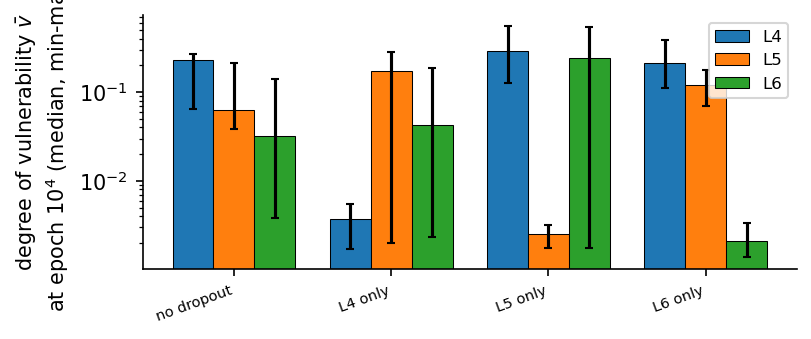

In [8]:
fig, ax = plt.subplots(figsize=(14*cm, 6*cm), dpi=150)
conds = [c for c, _, _ in ALL]
xs = np.arange(len(conds)); w = .26
for k, layer in enumerate(LAYER_LABELS):
    s = summary[summary.layer == layer].set_index("condition").loc[conds]
    ax.bar(xs + (k - 1) * w, s.deg_vuln, w,
           yerr=[s.deg_vuln - s.deg_vuln_min, s.deg_vuln_max - s.deg_vuln], capsize=2,
           color=COLORS[layer], edgecolor="k", lw=.5, label=layer)
ax.set_yscale("log"); ax.set_xticks(xs)
ax.set_xticklabels(conds, fontsize=7, rotation=20, ha="right")
ax.set_ylabel("degree of vulnerability $\\bar{v}$\nat epoch $10^4$ (median, min-max)")
ax.legend(fontsize=8); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

**Result.** Dropout drives the vulnerability of the layer it acts on down
by a factor of roughly 15-60 at epoch $10^4$ (table above), and the effect is
*local*: layers that do not receive dropout are unchanged or become *more*
vulnerable, as the network displaces single-neuron-critical structure onto
whichever layers are still unprotected.

## 4. Matched comparison: each layer with and without dropout on itself

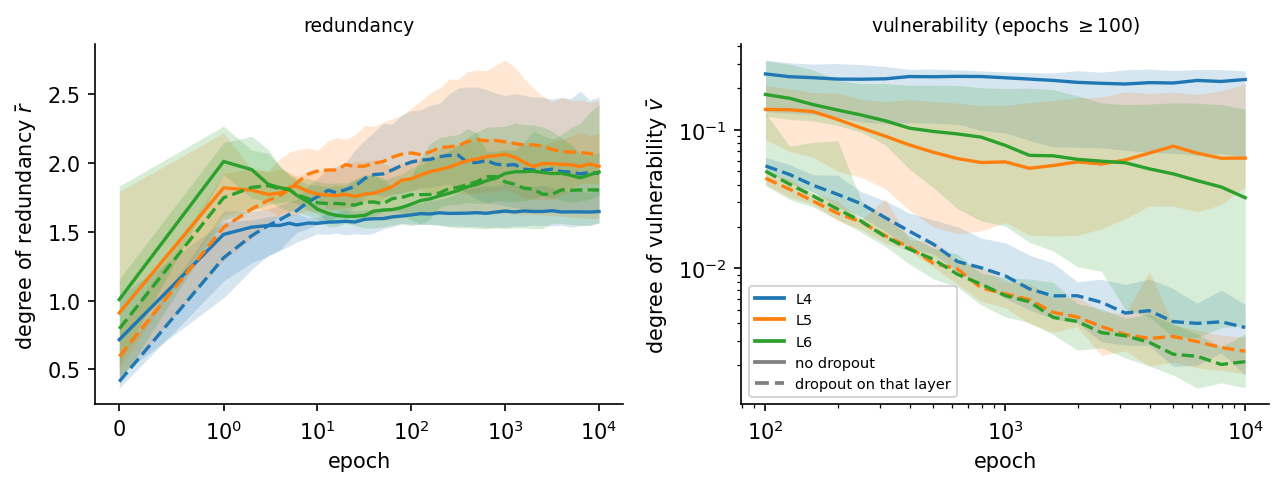

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(22*cm, 8.5*cm), dpi=150)
for layer, idx in zip(LAYER_LABELS, [0, 1, 2]):
    drop_id = PAPER_CONDITIONS[idx][1]          # dropout on this layer only
    for exp_id, ls in [(BASELINE, "-"), (drop_id, "--")]:
        d = observables(exp_id, layer)
        g = d.groupby(d.epoch_id.astype(int))["deg_red"]
        axes[0].fill_between(g.median().index, g.min(), g.max(),
                             alpha=.18, color=COLORS[layer], lw=0)
        axes[0].plot(g.median().index, g.median(), c=COLORS[layer], ls=ls, lw=1.6)
        dl = d[d.epoch_id >= 100]
        g = dl.groupby(dl.epoch_id.astype(int))["deg_vuln"]
        axes[1].fill_between(g.median().index, np.maximum(g.min(), 1e-5), g.max(),
                             alpha=.18, color=COLORS[layer], lw=0)
        axes[1].plot(g.median().index, g.median(), c=COLORS[layer], ls=ls, lw=1.6)
axes[0].set_xscale("symlog", linthresh=1)
axes[0].set_ylabel(r"degree of redundancy $\bar{r}$"); axes[0].set_title("redundancy", fontsize=9)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_ylabel(r"degree of vulnerability $\bar{v}$")
axes[1].set_title("vulnerability (epochs $\\geq$100)", fontsize=9)
for a in axes:
    a.set_xlabel("epoch"); a.spines[["top", "right"]].set_visible(False)
axes[1].legend(handles=[Line2D([], [], color=COLORS[l], lw=1.8, label=l) for l in LAYER_LABELS]
               + [Line2D([], [], color="gray", lw=1.8, ls="-", label="no dropout"),
                  Line2D([], [], color="gray", lw=1.8, ls="--", label="dropout on that layer")],
               fontsize=7, loc="lower left")
fig.tight_layout()

**Result.** Vulnerability falls by more than an order of magnitude, while
redundancy changes far less: at epoch $10^4$ it increases moderately in L4,
the first of the three layers, and stays within the run-to-run scatter in L5
and L6. The two Shannon observables are therefore not two views of one
underlying quantity: dropout changes *which* information is
single-neuron-critical without changing how many neurons can individually
supply a typical piece of information.

## 5. Cost in accuracy

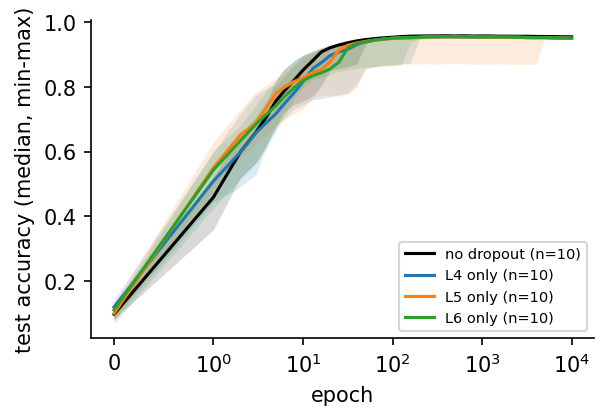

In [10]:
fig, ax = plt.subplots(figsize=(11*cm, 7*cm), dpi=150)
for (label, exp_id, _), col in zip(ALL, ["black", "tab:blue", "tab:orange",
                                         "tab:green", "tab:red", "tab:purple"]):
    path = nninfo.Experiment._find_experiment_dir(exp_id) / "performance_stochastic" / "results.h5"
    d = pd.read_hdf(path, "results")
    d = d[d.epoch_id <= 10_000]
    y = d[("full_set/test", "accuracy")]
    g = y.groupby(d.epoch_id.astype(int))
    ax.fill_between(g.median().index, g.min(), g.max(), alpha=.15, color=col, lw=0)
    ax.plot(g.median().index, g.median(), c=col, lw=1.5,
            label=f"{label} (n={d.run_id.nunique()})")
ax.set_xscale("symlog", linthresh=1)
ax.set_xlabel("epoch"); ax.set_ylabel("test accuracy (median, min-max)")
ax.legend(fontsize=7, loc="lower right"); ax.spines[["top", "right"]].set_visible(False)

**Result.** Dropout on a *single* layer costs almost nothing (about 0.4 pp of
test accuracy at epoch $10^4$), so a layer can be made essentially
invulnerable for free. With `INCLUDE_EXTRA_CONDITIONS = True`: protecting all
three five-neuron layers at once is a different matter -- it costs a great
deal of accuracy and the runs become bimodal. In a wider (3x8) network even
the all-layer condition is free -- the constraint only binds when the layers
are narrow.